# Pandas-Grundlagen: Zusammenfassung für die Prüfung

Dieses Notebook zeigt die wichtigsten Muster für DataFrames: Spalten auswählen, Kriterien formulieren, gruppieren, aggregieren und berechnete Werte wieder in ein DataFrame schreiben.

## 1. Spalten auswählen

```python
df["spalte"]                         # eine Spalte: Series
df[["spalte_a", "spalte_b"]]         # mehrere Spalten: DataFrame
```

Die äußeren Klammern gehören zum DataFrame-Zugriff. Die inneren Klammern bilden eine Python-Liste mit den gewünschten Spaltennamen. Deshalb braucht die Auswahl mehrerer Spalten `[[...]]`.

In [10]:
import pandas as pd

df = pd.DataFrame(
    {
        "chain": ["A", "A", "B", "B", "B"],
        "stars": [4.0, 5.0, 3.0, 4.0, 5.0],
        "review_count": [10, 20, 5, 15, 30],
    }
)

df["stars"]

0    4.0
1    5.0
2    3.0
3    4.0
4    5.0
Name: stars, dtype: float64

In [11]:
df[["chain", "stars"]]

,chain,stars
0,A,4.0
1,A,5.0
2,B,3.0
3,B,4.0
4,B,5.0


## 2. Kriterien (Filtern)

Ein Kriterium erzeugt eine boolesche Maske mit `True` und `False`. Diese Maske wird mit `.loc[...]` auf die Zeilen angewendet.

```python
maske = df["stars"] >= 4
ergebnis = df.loc[maske]
```

Mehrere Kriterien werden mit `&` (und) oder `|` (oder) verbunden. Jedes einzelne Kriterium steht in Klammern. Für "nicht gleich" verwendet man `!=`.

In [3]:
gute_bewertungen = df.loc[df["stars"] >= 4]
grosse_und_gute = df.loc[(df["review_count"] > 10) & (df["stars"] >= 4)]
ausgewaehlte_ketten = df.loc[df["chain"].isin(["A", "B"])]

grosse_und_gute

,chain,stars,review_count
1,A,5.0,20
3,B,4.0,15
4,B,5.0,30


## 3. Neue Spalte aus vorhandenen Spalten berechnen

Operationen auf Spalten werden automatisch elementweise für alle Zeilen ausgeführt.

```python
df["neue_spalte"] = df["spalte_a"] * df["spalte_b"]
```

Beispiel: Eine Bewertung wird mit der Anzahl ihrer Reviews gewichtet.

In [4]:
df["stars_x_reviews"] = df["stars"] * df["review_count"]
df[["stars", "review_count", "stars_x_reviews"]]

,stars,review_count,stars_x_reviews
0,4.0,10,40.0
1,5.0,20,100.0
2,3.0,5,15.0
3,4.0,15,60.0
4,5.0,30,150.0


## 4. Nur bei einem Kriterium einen Wert einfügen

Mit `.loc[maske, "spalte"]` werden nur die Zeilen beschrieben, die das Kriterium erfüllen. Das ist sicherer als eine Python-Schleife.

```python
df.loc[df["stars"] >= 4, "klasse"] = "gut"
df.loc[df["stars"] < 4, "klasse"] = "verbesserungswürdig"
```

Wenn alle Fälle in einer einzigen Anweisung behandelt werden sollen, ist `np.where(kriterium, wert_wenn_true, wert_wenn_false)` praktisch.

In [5]:
df.loc[df["stars"] >= 4, "klasse"] = "gut"
df.loc[df["stars"] < 4, "klasse"] = "verbesserungswürdig"
df[["stars", "klasse"]]

,stars,klasse
0,4.0,gut
1,5.0,gut
2,3.0,verbesserungswürdig
3,4.0,gut
4,5.0,gut


## 5. Gruppieren und aggregieren

Grundmuster:

```python
df.groupby("gruppen_spalte")["wert_spalte"].mean()
```

- `groupby("chain")`: bildet eine Gruppe pro Kette.
- `["stars"]`: wählt die auszuwertende Spalte.
- `.mean()`: berechnet den Mittelwert innerhalb jeder Gruppe.

Für mehrere Spalten braucht man wieder eine Liste: `[["stars", "review_count"]]`. Je nach Fragestellung sind auch `.sum()`, `.count()`, `.min()`, `.max()` oder `.median()` möglich.

In [8]:
mean_stars = df.groupby("chain")["stars"].mean()
totals = df.groupby("chain")[["stars_x_reviews", "review_count"]].sum()

mean_stars

chain
A    4.5
B    4.0
Name: stars, dtype: float64

In [7]:
totals

,stars_x_reviews,review_count
chain,,
A,140.0,30
B,225.0,50


## 6. Gruppenwert zurück in jede Zeile schreiben

Wenn jede Zeile den Mittelwert ihrer eigenen Gruppe erhalten soll, verwendet man `transform`. Anders als `groupby(...).mean()` behält `transform` die ursprüngliche Anzahl und den ursprünglichen Index der Zeilen bei.

```python
df["chain_mean_stars"] = df.groupby("chain")["stars"].transform("mean")
```

So kann man danach ein Kriterium auf Gruppenebene prüfen, aber trotzdem auf Zeilenebene filtern.

In [ ]:
df["chain_mean_stars"] = df.groupby("chain")["stars"].transform("mean")
df["chain_is_good"] = df["chain_mean_stars"] >= 4

df.loc[df["chain_is_good"], ["chain", "stars", "chain_mean_stars"]]

## 7. Häufige Prüfungsrezepte

```python
# Mittelwert pro Gruppe
df.groupby("gruppe")["wert"].mean()

# Nur Gruppen mit mindestens einem Kriterium behalten
df.groupby("gruppe").filter(lambda gruppe: gruppe["wert"].mean() >= 4)

# Gruppenwert als neue Spalte an jede Originalzeile anhängen
df["gruppenmittelwert"] = df.groupby("gruppe")["wert"].transform("mean")

# Danach nach diesem Gruppenwert filtern
df.loc[df["gruppenmittelwert"] >= 4]

# Einen berechneten Wert aus einer Ergebnis-Tabelle zuordnen
mittelwerte = df.groupby("gruppe")["wert"].mean()
df["gruppenmittelwert"] = df["gruppe"].map(mittelwerte)
```

### Merksatz

Erst klären: **Filtere ich Zeilen oder Gruppen?** Für Zeilen nutze ich `.loc`; für eine Zusammenfassung pro Gruppe `groupby` mit einer Aggregation; für einen Gruppenwert in den Originaldaten meistens `transform`.

## 8. Gruppierter Boxplot mit `matplotlib`

Aufgabe: Die bekannten Packungspreise (`price_chf`) nach Tierart (`animal`) vergleichen. Für jede Tierart wird eine eigene `Series` ausgewählt und als Liste an `ax.boxplot()` übergeben.

`dropna(subset=[...])` entfernt nur Zeilen, bei denen Tierart oder Preis fehlt. `tick_labels` beschriftet die drei Boxplots. `order` allein zeichnet keinen Plot und ist hier nicht nötig.

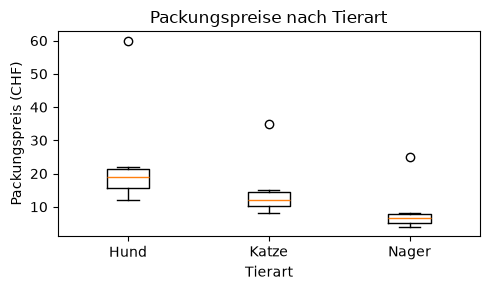

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Selbst erstellte Beispieldaten: Tierart und Packungspreis in CHF
df = pd.DataFrame(
    {
        "animal": [
            "Hund", "Hund", "Hund", "Hund", "Hund", "Hund",
            "Katze", "Katze", "Katze", "Katze", "Katze", "Katze",
            "Nager", "Nager", "Nager", "Nager", "Nager", "Nager",
        ],
        "price_chf": [
            12.0, 15.0, 18.0, 20.0, 22.0, 60.0,
            8.0, 10.0, 11.0, 13.0, 15.0, 35.0,
            4.0, 5.0, 6.0, 7.0, 8.0, 25.0,
        ],
    }
)

prices_hund = df.loc[df["animal"] == "Hund", "price_chf"]
prices_katze = df.loc[df["animal"] == "Katze", "price_chf"]
prices_nager = df.loc[df["animal"] == "Nager", "price_chf"]

fig, ax = plt.subplots(figsize=(5, 3))
ax.boxplot(
    [prices_hund, prices_katze, prices_nager],
    tick_labels=["Hund", "Katze", "Nager"],
)
ax.set_xlabel("Tierart")
ax.set_ylabel("Packungspreis (CHF)")
ax.set_title("Packungspreise nach Tierart")
plt.tight_layout()
plt.show()

### Boxplot richtig interpretieren

- Die Linie in der Box zeigt den **Median**. Er beschreibt den typischen mittleren Wert besser als der höchste Einzelpreis.
- Die Box zeigt den mittleren Bereich der Daten (vom 1. bis zum 3. Quartil).
- Punkte außerhalb der Whisker sind mögliche **Ausreißer**.
- Aus dem höchsten Punkt darf man nicht folgern, dass diese Tierart typischerweise am teuersten ist. Dafür vergleicht man vor allem die Mediane und die Lage der Boxen.
- Ausreißer löscht man nicht automatisch. Zuerst prüfen, ob sie echte Werte oder Eingabe-/Messfehler sind. Nur fehlerhafte Werte sollten korrigiert oder entfernt werden.

### Typische Prüfungsantworten

**a)** Die Aussage ist nicht ausreichend begründet, wenn sie nur auf dem höchsten Punkt basiert. Dieser kann ein Ausreißer sein. Für den typischen Preis muss man die Mediane beziehungsweise die Lage der Boxen vergleichen.

**b)** Das Vorgehen ist nicht automatisch sinnvoll. Einzelne Punkte sind mögliche Ausreißer, aber nicht zwingend falsche Daten. Sie dürfen nur nach einer fachlichen Prüfung entfernt werden.